
<img src="../../images/brownbear.png" width="400">

## A financial tool that can analyze and maximize investment portfolios on a risk adjusted basis  


Description: This notebook is useful for examining S&P 500 Sectors.  Construct portfolios from the S&P 500 Sector ETFs and examine the results of different weighting schemes.  In particular, we can select the best performing sectors over a given period.


In [1]:
%%javascript
IPython.OutputArea.prototype._should_scroll = function(lines) {
    return false;
}

<IPython.core.display.Javascript object>

In [2]:
# imports
import pandas as pd
import matplotlib.pyplot as plt
import brownbear as bb

# format price data
pd.options.display.float_format = '{:0.2f}'.format

# display all rows
pd.set_option('display.max_rows', None)

# do not truncate column names
pd.set_option('display.max_colwidth', None)

%matplotlib inline

In [3]:
# set size of inline plots
'''note: rcParams can't be in same cell as import matplotlib
   or %matplotlib inline
   
   %matplotlib notebook: will lead to interactive plots embedded within
   the notebook, you can zoom and resize the figure
   
   %matplotlib inline: only draw static images in the notebook
'''
plt.rcParams["figure.figsize"] = (10, 7)

### Some Globals

In [4]:
investment_universe = ['etf-galaxy']

In [5]:
# Fetch Investment Options - all values annualized
df = bb.fetch(investment_universe, risk_free_rate=0, annual_returns='1 Yr')
df

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
0,SPY,S&P 500 ETF,US Stocks:Large Cap,49.51,27.03,30.19,29.11,23.82,14.31,9.51,4.71,12.58,13.07,15.72,30.19,13.07,2.31
1,DIA,DJIA ETF,US Stocks:Large Cap,19.89,19.15,23.06,21.46,17.51,10.24,10.32,5.49,9.91,12.26,14.85,23.06,12.26,1.88
2,QQQ,Nasdaq 100 ETF,US Stocks:Growth,119.56,47.78,42.97,41.81,31.12,18.40,15.69,6.04,19.24,17.00,20.72,42.97,17.00,2.53
3,VTI,Vanguard Total Stock Market Index ETF,US Stocks:Total Stock Market,48.08,27.30,30.34,29.27,23.51,13.20,9.91,4.95,12.44,13.54,15.96,30.34,13.54,2.24
4,IWM,Russell 2000 ETF,US Stocks:Small Cap,53.45,41.82,42.84,42.12,19.27,7.02,18.98,10.24,14.30,20.08,20.62,42.84,20.08,2.13
5,MDY,S&P 400 Midcap ETF,US Stocks:Mid Cap,19.31,30.73,25.37,23.49,16.50,8.04,15.01,7.41,10.55,16.16,17.97,25.37,16.16,1.57
6,IWD,Russell 1000 Value ETF,US Stocks:Value,25.86,34.11,28.95,27.95,18.68,10.43,10.10,5.66,10.19,12.86,14.84,28.95,12.86,2.25
7,IWF,Russell 1000 Growth ETF,US Stocks:Growth,67.10,18.33,28.87,27.57,27.35,15.91,11.01,4.91,16.59,16.22,19.23,28.87,16.22,1.78
8,RSP,S&P 500 Equal Weight ETF,US Stocks:Growth,9.61,23.88,20.60,19.24,15.74,8.71,9.15,4.67,9.88,13.53,15.77,20.60,13.53,1.52
9,SPSM,S&P 600 Small Cap ETF,US Stocks:Small Cap,31.39,34.94,33.41,32.95,15.50,6.39,15.16,7.82,12.81,19.27,19.83,33.41,19.27,1.73


In [6]:
# Sector Ranking
sector_rank = bb.rank(df, rank_by='Sharpe Ratio')
sector_rank = sector_rank[sector_rank['Description'].str.contains('Sector ETF')]
#sector_rank = sector_rank.loc[(sector_rank['3 mo'] > 0) & sector_rank['1 Yr'] > 0]
#sector_rank = rank_filtered.head(10)
sector_rank

,Investment Option,Description,Asset Class,3 mo,6 mo,1 Yr,1-1 Yr,3 Yr,5 Yr,Vola,DS Vola,SD 1 Yr,SD 3 Yr,SD 5 Yr,Annual Returns,Std Dev,Sharpe Ratio
19,XLK,S&P500 Technology Sector ETF,US Stocks:Technology,260.92,86.58,66.16,61.86,35.89,23.85,22.95,8.48,28.25,22.20,23.65,66.16,22.20,2.98
16,XLE,S&P500 Energy Sector ETF,US Stocks:Energy,5.38,66.34,42.31,42.15,15.69,21.03,27.28,18.32,19.27,18.99,25.67,42.31,18.99,2.23
18,XLI,S&P500 Industrials Sector ETF,US Stocks:Industrials,-7.72,31.50,23.05,22.91,22.47,12.64,17.08,8.81,14.77,16.50,18.15,23.05,16.50,1.40
14,XLB,S&P500 Materials Sector ETF,US Stocks:Materials,-14.37,38.35,21.27,20.11,12.10,5.47,19.93,13.18,15.39,16.76,19.42,21.27,16.76,1.27
23,XLV,S&P500 Healthcare Sector ETF,US Stocks:Healthcare,-22.96,-9.88,15.71,16.20,6.52,5.43,13.09,5.86,14.62,13.60,14.66,15.71,13.60,1.16
15,XLC,S&P500 Communication Services Sector ETF,US Stocks:Communication Services,-6.58,3.77,15.05,16.01,25.01,9.63,10.52,6.17,13.19,13.08,18.28,15.05,13.08,1.15
22,XLU,S&P500 Utilities Sector ETF,US Stocks:Utilities,-22.87,3.00,13.46,12.40,13.90,9.34,14.16,10.14,14.68,14.93,16.52,13.46,14.93,0.90
24,XLY,S&P500 Consumer Discretionary Sector ETF,US Stocks:Consumer Discretionary,15.37,8.13,13.39,13.45,18.28,8.36,15.90,8.14,12.85,18.49,22.19,13.39,18.49,0.72
21,XLRE,S&P500 Real Estate Sector ETF,US Stocks:Real Estate,4.13,17.56,10.19,11.24,10.65,4.15,11.48,6.85,13.08,16.77,19.28,10.19,16.77,0.61
20,XLP,S&P500 Consumer Staples Sector ETF,US Stocks:Consumer Staples,-26.38,15.92,4.19,5.37,6.62,5.90,13.37,8.32,15.30,12.13,13.43,4.19,12.13,0.35


### Sample Portfolios
Format 'Investment option': weight

In [7]:
# S&P 500 Sectors - top 4
top_sectors_portfolio = {
    'Title': 'Top S&P500 Sectors Portfolio'
}
top_sectors = list(sector_rank['Investment Option'])[:4]
top_sectors_portfolio.update(dict.fromkeys(top_sectors, 1/len(top_sectors)))

# S&P 500 Sectors - all
all_sectors_portfolio = {
    'Title': 'All S&P500 Sectors Portfolio'
}
all_sectors = list(sector_rank['Investment Option'])
all_sectors_portfolio.update(dict.fromkeys(all_sectors, 1/len(all_sectors)))

### Custom Portfolios

In [8]:
# my portfolio
my_portfolio = {
    'Title': 'My Portfolio',

}

### Choose Portfolio Option

In [9]:
# Select one of the portfolios from above
portfolio_option = all_sectors_portfolio

In [10]:
# Make a copy so that the original portfolio is preserved
portfolio_option = portfolio_option.copy()

### Analysis Options

In [11]:
# Specify the weighting scheme.  It will replace the weights specified in the portfolio
# You can also fix the weights on some Investent Options, Asset Classes, and Asset Subclasses
# while the others are automatically calculated.

# 'Equal' - will use equal weights.

# 'Sharpe Ratio' - will use proportionally weighted # allocations based on the percent
#  of an investment option's sharpe ratio to the sum of all the sharpe ratios in the portfolio.

# 'Std Dev' - will use standard deviation adjusted weights

# 'Annual Returns' - will use return adjusted weights

# 'Vola' - will use volatility adjusted weights

# 'DS Vola' - will use downside volatility adjusted weights

# None: 'Investment Option' means use user specified weights
#       'Asset Class' means do not group by Asset Class
#       'Asset Subclass means do not group by Asset Subclass 

weight_by = {
    'Asset Class':       {'weight_by': None},
    'Asset Subclass':    {'weight_by': None},
    'Investment Option': {'weight_by': 'DS Vola'},
}

In [12]:
bb.DEBUG = False

# Analyze portfolio
annual_ret, std_dev, sharpe_ratio = \
    bb.analyze(df, portfolio_option, weight_by)

,XLK,XLE,XLI,XLB,XLV,XLC,XLU,XLY,XLRE,XLP,XLF,All S&P500 Sectors Portfolio
Annual Returns,66.16,42.31,23.05,21.27,15.71,15.05,13.46,13.39,10.19,4.19,3.53,19.80
Std Dev,22.20,18.99,16.50,16.76,13.60,13.08,14.93,18.49,16.77,12.13,14.42,10.13
Sharpe Ratio,2.98,2.23,1.40,1.27,1.16,1.15,0.90,0.72,0.61,0.35,0.24,1.95
Weight,0.10,0.05,0.10,0.07,0.10,0.10,0.10,0.10,0.10,0.10,0.10,1.00
Worst Typical Down Year,21.76,4.33,-9.95,-12.25,-11.49,-11.11,-16.40,-23.59,-23.35,-20.07,-25.31,-0.46
Black Swan,-0.44,-14.66,-26.45,-29.01,-25.09,-24.19,-31.33,-42.08,-40.12,-32.20,-39.73,-10.59


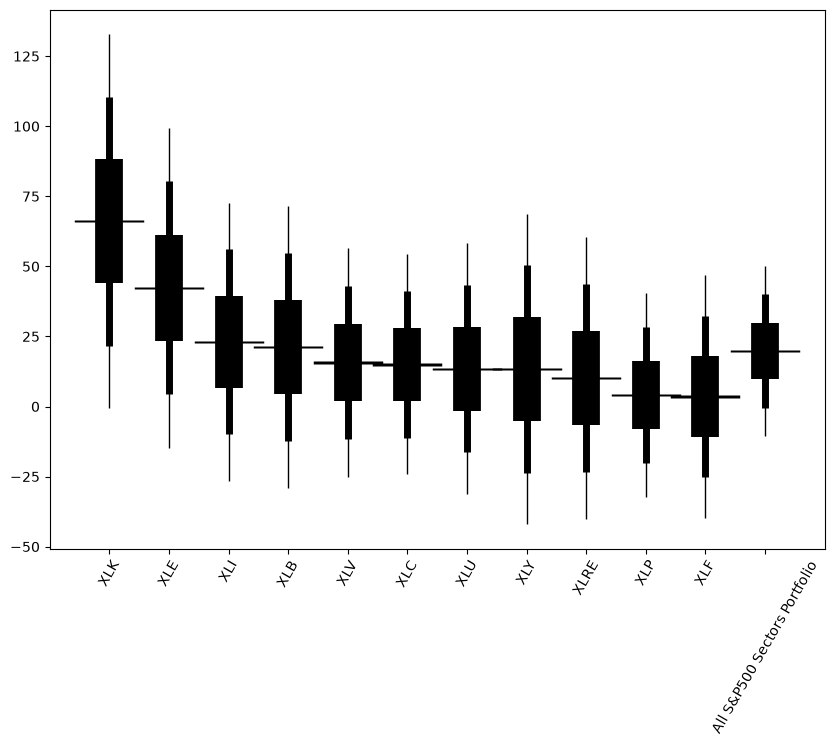

In [13]:
# Display Results
summary = bb.summary(df, portfolio_option, annual_ret, std_dev, sharpe_ratio)
summary

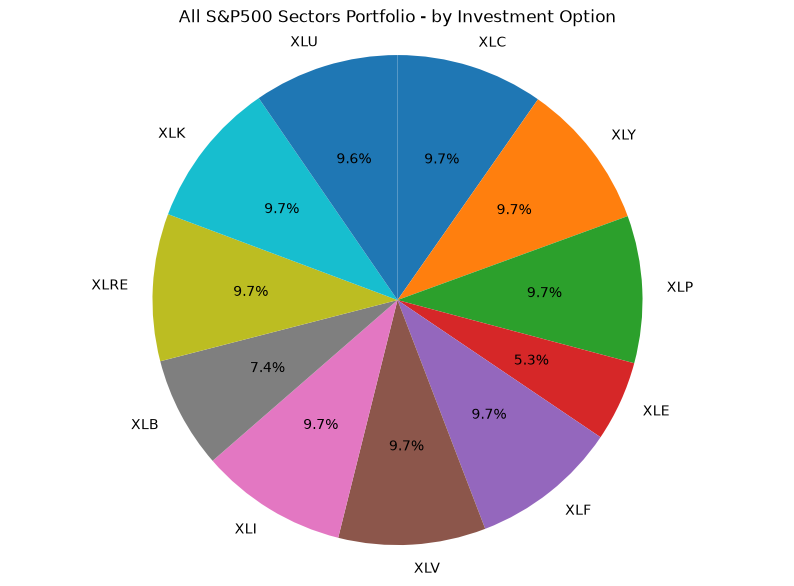

XLC    0.10
XLY    0.10
XLP    0.10
XLE    0.05
XLF    0.10
XLV    0.10
XLI    0.10
XLB    0.07
XLRE   0.10
XLK    0.10
XLU    0.10



In [14]:
# Show pie charts of investment and asset class weights
bb.show_pie_charts(df, portfolio_option, charts=['Investment Option'])

In [15]:
# Show exact weights
bb.print_portfolio(portfolio_option)

All S&P500 Sectors Portfolio Weights:
    XLK                            0.0972
    XLE                            0.0530
    XLI                            0.0972
    XLB                            0.0737
    XLV                            0.0972
    XLC                            0.0972
    XLU                            0.0958
    XLY                            0.0972
    XLRE                           0.0972
    XLP                            0.0972
    XLF                            0.0972


### Optimize Portfolio

In [16]:
# Run_portfolio_optimizer = True will run portfolio optimizer after portfolio analysis is complete
run_portfolio_optimizer = False

In [17]:
# Optimize sharpe ratio while specifying Annual Rate, Worst Typical Down Year,
# and Black Swan.  Setting a constraint to None optimizes absolute Sharpe Ratio
# without regard to that constraint.

'''
constraints = {
    'Annual Return': 12,
    'Worst Typical Down Year': -5,
    'Black Swan': None
}
'''

constraints = {
    'Annual Return': 8,
    'Worst Typical Down Year': None,
    'Black Swan': -40
}

if run_portfolio_optimizer:
    bb.optimizer(df, portfolio_option, constraints)

### Use Sharpe Ratio adjusted weights
Recommend that you also try using Sharpe Ratio adjusted weights and compare those results with the Optimized Portflio.  
It tends to produce a higher Annual Return while keeping the allocations more balanced than the Optimizer.  (See 'Analysis Options' section).